In [1]:
import statsmodels.api as sm 
import pandas as pd
import numpy as np

In [2]:
import os
import io
import gzip
import json
import shutil
import requests
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

c:\Users\peace\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
# Download latest version
path = kagglehub.dataset_download("ammaraahmad/us-ecommerce-record-2020")

ecom_data_df = pd.read_csv(os.path.join(path, os.listdir(path)[0]), encoding='latin1')
ecom_data_df.to_csv("ecommerce_data.csv", index=False)
ecom_data_df.head()

,Order Date,Row ID,Order ID,Ship Mode,Customer ID,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,01-01-20,849,CA-2017-107503,Standard Class,GA-14725,Consumer,United States,Lorain,Ohio,44052,East,FUR-FU-10003878,Furniture,Furnishings,"Linden 10"" Round Wall Clock, Black",48.896,4,0.2,8.5568
1,01-01-20,4010,CA-2017-144463,Standard Class,SC-20725,Consumer,United States,Los Angeles,California,90036,West,FUR-FU-10001215,Furniture,Furnishings,"Howard Miller 11-1/2"" Diameter Brentwood Wall ...",474.430,11,0.0,199.2606
2,01-01-20,6683,CA-2017-154466,First Class,DP-13390,Home Office,United States,Franklin,Wisconsin,53132,Central,OFF-BI-10002012,Office Supplies,Binders,Wilson Jones Easy Flow II Sheet Lifters,3.600,2,0.0,1.7280
3,01-01-20,8070,CA-2017-151750,Standard Class,JM-15250,Consumer,United States,Huntsville,Texas,77340,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,454.560,5,0.2,-107.9580
4,01-01-20,8071,CA-2017-151750,Standard Class,JM-15250,Consumer,United States,Huntsville,Texas,77340,Central,FUR-FU-10002116,Furniture,Furnishings,"Tenex Carpeted, Granite-Look or Clear Contempo...",141.420,5,0.6,-187.3815


In [9]:
# The base URL provided by the lab (raw review categories)
BASE_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/"

# List of some categories to sample (you can add all 33+ here)
categories = [
    "All_Beauty", "Amazon_Fashion", "Appliances", "Arts_Crafts_and_Sewing",
    "Automotive", "Baby_Products", "Beauty_and_Personal_Care", "Books",
    "CDs_and_Vinyl", "Cell_Phones_and_Accessories", "Clothing_Shoes_and_Jewelry",
    "Digital_Music", "Electronics", "Gift_Cards", "Grocery_and_Gourmet_Food",
    "Handmade_Products", "Health_and_Household", "Health_and_Personal_Care",
    "Home_and_Kitchen", "Industrial_and_Scientific", "Kindle_Store",
    "Magazine_Subscriptions", "Movies_and_TV", "Musical_Instruments",
    "Office_Products", "Patio_Lawn_and_Garden", "Pet_Supplies", "Software",
    "Sports_and_Outdoors", "Subscription_Boxes", "Tools_and_Home_Improvement",
    "Toys_and_Games", "Video_Games", "Unknown"
]

def sample_amazon_dataset(category_list, sample_size=100):
    all_data = []

    for cat in category_list:
        # Construct the direct download URL for the compressed jsonl file
        # Note: The server might require specific headers or a direct file path
        url = f"{BASE_URL}{cat}.jsonl.gz"
        print(f"Streaming sample from {cat}...")

        try:
            # Stream the file from the URL
            response = requests.get(url, stream=True)
            response.raise_for_status()

            # Decompress on the fly
            with gzip.open(response.raw, 'rt', encoding='utf-8') as f:
                cat_sample = []
                for i, line in enumerate(f):
                    cat_sample.append(json.loads(line))
                    if i >= sample_size - 1:
                        break
                
                # Convert this category's sample to a DataFrame
                df_temp = pd.DataFrame(cat_sample)
                df_temp['category_name'] = cat
                all_data.append(df_temp)
                print(f"  Successfully sampled {len(df_temp)} rows.")

        except Exception as e:
            print(f"  Failed to stream {cat}: {e}")

    # Compile all samples into one master DataFrame
    if all_data:
        amazon_review_df = pd.concat(all_data, ignore_index=True)
        return amazon_review_df
    return pd.DataFrame()

# Execute sampling
amazon_review_df = sample_amazon_dataset(categories, sample_size=100000)
amazon_review_df_small = sample_amazon_dataset(categories, sample_size=300)  # ~10k rows across 33 categories
amazon_review_df_small.to_csv("amazon_review_data.csv", index=False)
print(amazon_review_df.info())

Streaming sample from All_Beauty...


  Successfully sampled 100000 rows.
Streaming sample from Amazon_Fashion...
  Successfully sampled 100000 rows.
Streaming sample from Appliances...
  Successfully sampled 100000 rows.
Streaming sample from Arts_Crafts_and_Sewing...
  Successfully sampled 100000 rows.
Streaming sample from Automotive...
  Successfully sampled 100000 rows.
Streaming sample from Baby_Products...
  Successfully sampled 100000 rows.
Streaming sample from Beauty_and_Personal_Care...
  Successfully sampled 100000 rows.
Streaming sample from Books...
  Successfully sampled 100000 rows.
Streaming sample from CDs_and_Vinyl...
  Successfully sampled 100000 rows.
Streaming sample from Cell_Phones_and_Accessories...
  Successfully sampled 100000 rows.
Streaming sample from Clothing_Shoes_and_Jewelry...
  Successfully sampled 100000 rows.
Streaming sample from Digital_Music...
  Successfully sampled 100000 rows.
Streaming sample from Electronics...
  Successfully sampled 100000 rows.
Streaming sample from Gift_Cards

In [8]:
# Clear the cached dataset
cache_path = os.path.expanduser("~/.cache/kagglehub/datasets/psparks/instacart-market-basket-analysis")
if os.path.exists(cache_path):
    shutil.rmtree(cache_path)
    print("Cache cleared")

# Fresh download, then read everything with pandas directly
dataset_path = kagglehub.dataset_download("psparks/instacart-market-basket-analysis")

aisles_df               = pd.read_csv(f"{dataset_path}/aisles.csv")
departments_df          = pd.read_csv(f"{dataset_path}/departments.csv")
order_products_prior_df = pd.read_csv(f"{dataset_path}/order_products__prior.csv", encoding="ISO-8859-1")
order_products_train_df = pd.read_csv(f"{dataset_path}/order_products__train.csv")
products_df             = pd.read_csv(f"{dataset_path}/products.csv")
order_df                = pd.read_csv(f"{dataset_path}/orders.csv")

print("All files loaded successfully")
# Merge all dataframes into one
insta_df = (
    order_products_prior_df
    .merge(order_df, on="order_id")
    .merge(products_df, on="product_id")
    .merge(aisles_df, on="aisle_id")
    .merge(departments_df, on="department_id")
)
insta_df_sample_small = insta_df.sample(15_000, random_state=42)
insta_df_sample_small.to_csv("insta_df_sample.csv", index=False)
print(insta_df.shape)
print(insta_df.head())

Cache cleared


100%|██████████| 197M/197M [00:06<00:00, 34.3MB/s] 

Extracting files...


All files loaded successfully
(32434489, 15)
   order_id  product_id  add_to_cart_order  reordered  user_id eval_set  \
0         2       33120                  1          1   202279    prior   
1         2       28985                  2          1   202279    prior   
2         2        9327                  3          0   202279    prior   
3         2       45918                  4          1   202279    prior   
4         2       30035                  5          0   202279    prior   

   order_number  order_dow  order_hour_of_day  days_since_prior_order  \
0             3          5                  9                     8.0   
1             3          5                  9                     8.0   
2             3          5                  9                     8.0   
3             3          5                  9                     8.0   
4             3          5                  9                     8.0   

            product_name  aisle_id  department_id               a

In [24]:
ecom_data_df_test=ecom_data_df[['Sales', 'Profit']]
ecom_data_df_test.head()
ecom_x = ecom_data_df_test[['Sales']]
ecom_y = ecom_data_df_test[['Profit']]
# Tesing the statsmodels library for linear regression
df_x = sm.add_constant(ecom_x)  # adding a constant
model = sm.OLS(ecom_y, df_x).fit()
results = model.summary()
print(results)

                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.283
Model:                            OLS   Adj. R-squared:                  0.283
Method:                 Least Squares   F-statistic:                     1309.
Date:                Sun, 06 Sep 2026   Prob (F-statistic):          8.76e-242
Time:                        12:46:51   Log-Likelihood:                -22325.
No. Observations:                3312   AIC:                         4.465e+04
Df Residuals:                    3310   BIC:                         4.467e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -20.4880      3.804     -5.385      0.0

In [25]:
# Testing quadratic inclusion for multicollinearity
ecom_data_df_test = ecom_data_df_test.join(ecom_data_df_test['Sales']**2, lsuffix='_orig', rsuffix='_quad')
ecom_data_df_test.head()

,Sales_orig,Profit,Sales_quad
0,48.896,8.5568,2390.818816
1,474.430,199.2606,225083.824900
2,3.600,1.7280,12.960000
3,454.560,-107.9580,206624.793600
4,141.420,-187.3815,19999.616400


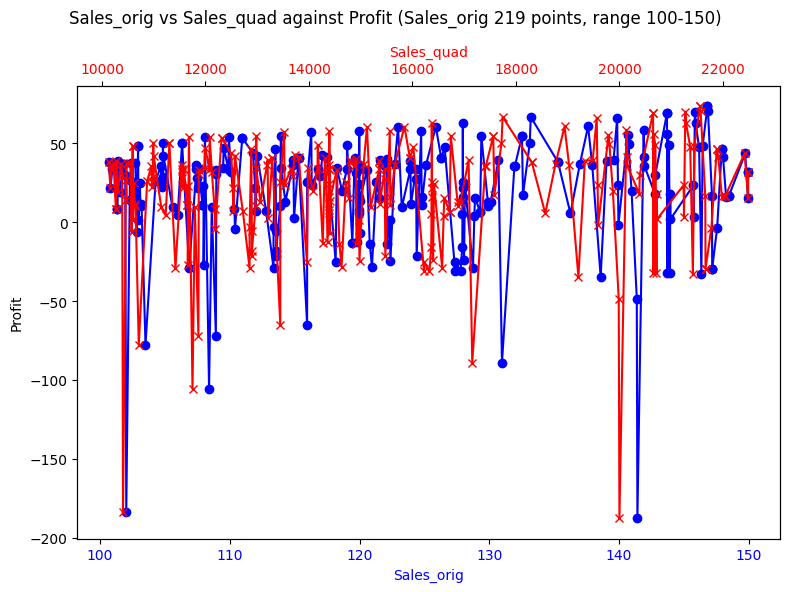

In [33]:
# Pick a narrow range of Sales_orig to demonstrate near-linearity
mask = ecom_data_df_test['Sales_orig'].between(100, 150)  # adjust based on your data's density
subset = ecom_data_df_test[mask].sort_values('Sales_orig')

fig, ax1 = plt.subplots(figsize=(8, 6))

# Plot Sales_orig vs Profit on primary x-axis
ax1.plot(subset['Sales_orig'], subset['Profit'], color='blue', marker='o', label='Sales_orig')
ax1.set_xlabel('Sales_orig', color='blue')
ax1.set_ylabel('Profit')
ax1.tick_params(axis='x', labelcolor='blue')

# Plot Sales_quad vs Profit on secondary x-axis (top), sharing the same y-axis
ax2 = ax1.twiny()
ax2.plot(subset['Sales_quad'], subset['Profit'], color='red', marker='x', label='Sales_quad')
ax2.set_xlabel('Sales_quad', color='red')
ax2.tick_params(axis='x', labelcolor='red')

fig.suptitle(f'Sales_orig vs Sales_quad against Profit (Sales_orig {mask.sum()} points, range 100-150)')
fig.tight_layout()
plt.show()

In [36]:
# Testing interaction terms
ecom_data_df_test = ecom_data_df[['Sales', 'Profit', 'Quantity']].copy()
ecom_data_df_test['Sales_Quantity'] = ecom_data_df_test['Sales'] * ecom_data_df_test['Quantity']

# Model WITHOUT interaction term
X_no_interaction = sm.add_constant(ecom_data_df_test[['Sales', 'Quantity']])
y = ecom_data_df_test['Profit']

model_no_interaction = sm.OLS(y, X_no_interaction).fit()
print("=== Without interaction term ===")
print(model_no_interaction.summary())

# Model WITH interaction term
X_with_interaction = sm.add_constant(ecom_data_df_test[['Sales', 'Quantity', 'Sales_Quantity']])

model_with_interaction = sm.OLS(y, X_with_interaction).fit()
print("\n=== With interaction term ===")
print(model_with_interaction.summary())

=== Without interaction term ===
                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.286
Model:                            OLS   Adj. R-squared:                  0.285
Method:                 Least Squares   F-statistic:                     661.9
Date:                Sun, 06 Sep 2026   Prob (F-statistic):          1.59e-242
Time:                        13:06:30   Log-Likelihood:                -22319.
No. Observations:                3312   AIC:                         4.464e+04
Df Residuals:                    3309   BIC:                         4.466e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.94

In [37]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
# --- VIF for model WITHOUT interaction ---
X_no_interaction = ecom_data_df_test[['Sales', 'Quantity']]
X_no_interaction_const = sm.add_constant(X_no_interaction)

vif_no_interaction = pd.DataFrame()
vif_no_interaction['Variable'] = X_no_interaction_const.columns
vif_no_interaction['VIF'] = [variance_inflation_factor(X_no_interaction_const.values, i) 
                               for i in range(X_no_interaction_const.shape[1])]

print("=== VIF without interaction term ===")
print(vif_no_interaction)

# --- VIF for model WITH interaction ---
X_with_interaction = ecom_data_df_test[['Sales', 'Quantity', 'Sales_Quantity']]
X_with_interaction_const = sm.add_constant(X_with_interaction)

vif_with_interaction = pd.DataFrame()
vif_with_interaction['Variable'] = X_with_interaction_const.columns
vif_with_interaction['VIF'] = [variance_inflation_factor(X_with_interaction_const.values, i) 
                                 for i in range(X_with_interaction_const.shape[1])]

print("\n=== VIF with interaction term ===")
print(vif_with_interaction)

=== VIF without interaction term ===
   Variable       VIF
0     const  1.000000
1     Sales  1.037915
2  Quantity  1.037915

=== VIF with interaction term ===
         Variable       VIF
0           const  1.000000
1           Sales  5.611982
2        Quantity  1.290709
3  Sales_Quantity  6.237904


In [38]:
ecom_data_df.head()

,Order Date,Row ID,Order ID,Ship Mode,Customer ID,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,01-01-20,849,CA-2017-107503,Standard Class,GA-14725,Consumer,United States,Lorain,Ohio,44052,East,FUR-FU-10003878,Furniture,Furnishings,"Linden 10"" Round Wall Clock, Black",48.896,4,0.2,8.5568
1,01-01-20,4010,CA-2017-144463,Standard Class,SC-20725,Consumer,United States,Los Angeles,California,90036,West,FUR-FU-10001215,Furniture,Furnishings,"Howard Miller 11-1/2"" Diameter Brentwood Wall ...",474.430,11,0.0,199.2606
2,01-01-20,6683,CA-2017-154466,First Class,DP-13390,Home Office,United States,Franklin,Wisconsin,53132,Central,OFF-BI-10002012,Office Supplies,Binders,Wilson Jones Easy Flow II Sheet Lifters,3.600,2,0.0,1.7280
3,01-01-20,8070,CA-2017-151750,Standard Class,JM-15250,Consumer,United States,Huntsville,Texas,77340,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,454.560,5,0.2,-107.9580
4,01-01-20,8071,CA-2017-151750,Standard Class,JM-15250,Consumer,United States,Huntsville,Texas,77340,Central,FUR-FU-10002116,Furniture,Furnishings,"Tenex Carpeted, Granite-Look or Clear Contempo...",141.420,5,0.6,-187.3815


In [39]:
categorical_cols = ['Ship Mode', 'Segment', 'Region', 'Category', 'Sub-Category']
continuous_cols = ['Sales', 'Quantity', 'Discount']
target_col = 'Profit'

In [40]:
for col in ['City', 'State', 'Postal Code', 'Country', 'Customer ID', 'Product ID']:
    print(f"{col}: {ecom_data_df[col].nunique()} unique values")

City: 350 unique values
State: 47 unique values
Postal Code: 437 unique values
Country: 1 unique values
Customer ID: 693 unique values
Product ID: 1525 unique values


In [41]:
# One-hot encode categorical columns, dropping first category to avoid dummy variable trap
X_categorical = pd.get_dummies(ecom_data_df[categorical_cols], drop_first=True)

# Combine with continuous features
X = pd.concat([ecom_data_df[continuous_cols], X_categorical], axis=1)
y = ecom_data_df[target_col]

print(X.head())
print(f"\nTotal features after encoding: {X.shape[1]}")

     Sales  Quantity  Discount  Ship Mode_Same Day  Ship Mode_Second Class  \
0   48.896         4       0.2               False                   False   
1  474.430        11       0.0               False                   False   
2    3.600         2       0.0               False                   False   
3  454.560         5       0.2               False                   False   
4  141.420         5       0.6               False                   False   

   Ship Mode_Standard Class  Segment_Corporate  Segment_Home Office  \
0                      True              False                False   
1                      True              False                False   
2                     False              False                 True   
3                      True              False                False   
4                      True              False                False   

   Region_East  Region_South  ...  Sub-Category_Envelopes  \
0         True         False  ...          

In [ ]:
X_const = sm.add_constant(X.astype(float))  # ensure all dummy 0/1 columns are numeric
model = sm.OLS(y, X_const).fit()
print(model.summary())

# High t value indicates that the coefficient is significantly different from zero, suggesting a strong relationship with the target variable. If t is small (close to zero), it suggests that the predictor may not be significantly contributing to the model.
# p-value indicates the probability of observing the data given that the null hypothesis is true. A low p-value (typically < 0.05) suggests that we can reject the null hypothesis, indicating that the predictor is statistically significant in explaining the variability in the target variable.

                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.408
Model:                            OLS   Adj. R-squared:                  0.403
Method:                 Least Squares   F-statistic:                     83.74
Date:                Sun, 06 Sep 2026   Prob (F-statistic):               0.00
Time:                        13:09:56   Log-Likelihood:                -22009.
No. Observations:                3312   AIC:                         4.407e+04
Df Residuals:                    3284   BIC:                         4.425e+04
Df Model:                          27                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

C:\Users\peace\AppData\Local\Temp\ipykernel_21204\3180750060.py:2: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y, X_const).fit()
